In [16]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

print(" Libraries imported successfully!")

 Libraries imported successfully!


In [10]:

df = pd.read_csv(r"C:\Users\DELL\OneDrive\Statatics_projects\spread_locator_dataset - spread_locator_dataset.csv.csv")

In [11]:
df.shape

(220, 7)

In [13]:
df['transaction_status'].value_counts()

transaction_status
Fail       122
Success     98
Name: count, dtype: int64

In [14]:
success = (df['transaction_status'] == 'Success').sum()

total = len(df)

p = success / total
q = 1 - p

print("Probability of Success:", p)
print("Probability of Failure:", q)

Probability of Success: 0.44545454545454544
Probability of Failure: 0.5545454545454546


#### Bernoulli Distribution Visualization ###

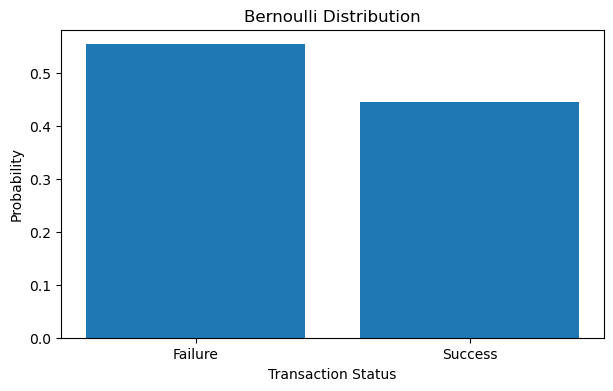

In [17]:
plt.figure(figsize=(7, 4))

plt.bar(['Failure', 'Success'], [q, p])

plt.title('Bernoulli Distribution')
plt.xlabel('Transaction Status')
plt.ylabel('Probability')

plt.show()

#### Binomial Distribution ###

Total Trials: 10
Successful Trials: 7
Probability: 0.07122237631521985


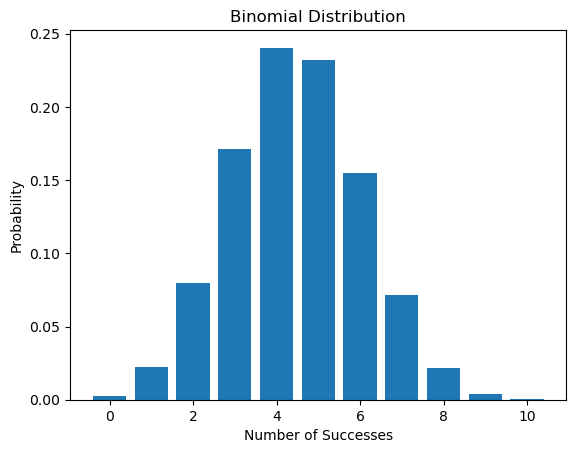

In [18]:

from scipy.stats import binom
import numpy as np
import matplotlib.pyplot as plt

n = 10
k = 7

p = success / total

result = binom.pmf(k, n, p)

print("Total Trials:", n)
print("Successful Trials:", k)
print("Probability:", result)

x = np.arange(0, n + 1)
y = binom.pmf(x, n, p)

plt.bar(x, y)
plt.title("Binomial Distribution")
plt.xlabel("Number of Successes")
plt.ylabel("Probability")
plt.show()

## Poisson Distribution ##

Average Daily Transactions: 7.096774193548387


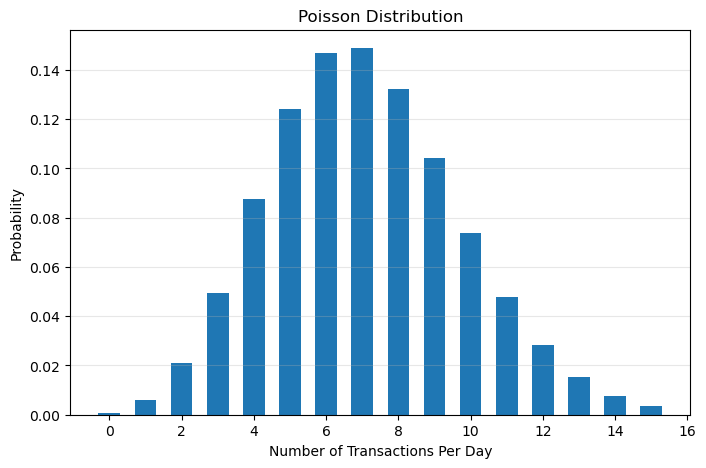

In [21]:

df['transaction_date'] = pd.to_datetime(df['transaction_date'])

daily_count = df.groupby(df['transaction_date'].dt.date).size()

lam = daily_count.mean()

print("Average Daily Transactions:", lam)

x = np.arange(0, 16)
probability = stats.poisson.pmf(x, lam)

plt.figure(figsize=(8, 5))

plt.bar(x, probability, width=0.6)

plt.xlabel("Number of Transactions Per Day")
plt.ylabel("Probability")
plt.title("Poisson Distribution")

plt.grid(axis='y', alpha=0.3)

plt.savefig("Poisson_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

3. #### Log Normal Distribution & Power Law ####

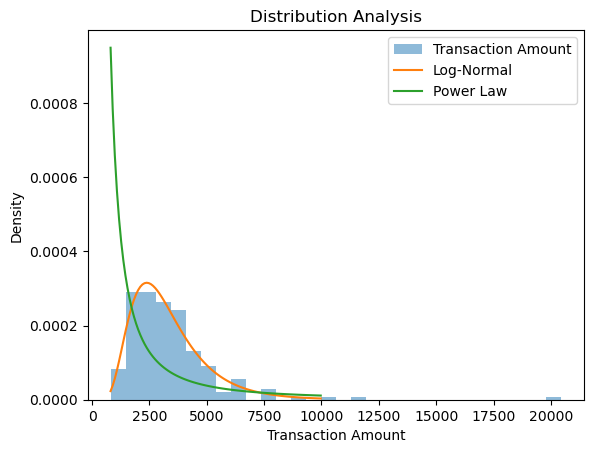

In [26]:

amount = df['transaction_amount'].dropna()
amount = amount[amount > 0]

a, b, c = stats.lognorm.fit(amount, floc=0)


p, q, r = stats.pareto.fit(amount, floc=0)

x = np.linspace(amount.min(), amount.quantile(0.99), 100)

y1 = stats.lognorm.pdf(x, a, b, c)
y2 = stats.pareto.pdf(x, p, q, r)

plt.hist(amount, bins=30, density=True, alpha=0.5, label='Transaction Amount')
plt.plot(x, y1, label='Log-Normal')
plt.plot(x, y2, label='Power Law')

plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.title("Distribution Analysis")
plt.legend()
plt.show()

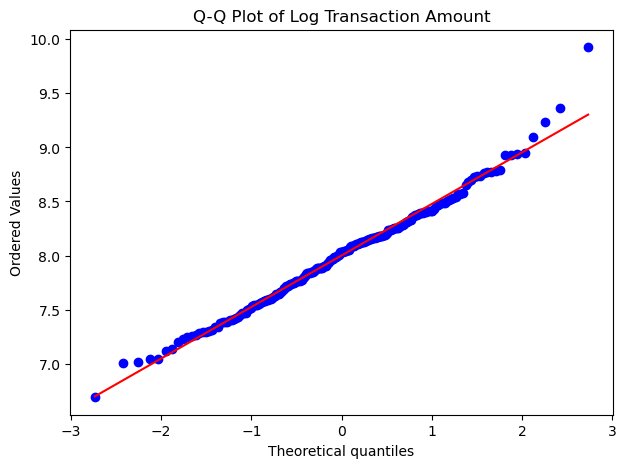

In [29]:
log_amount = np.log(amount)

plt.figure(figsize=(7, 5))

stats.probplot(log_amount, dist="norm", plot=plt)

plt.title("Q-Q Plot of Log Transaction Amount")
plt.show()

In [37]:
Amount = df['transaction_amount']

Transformed, Lambda = stats.boxcox(Amount)

print("Lambda:", Lambda)
print("Original Skewness:", stats.skew(Amount))
print("Transformed Skewness:", stats.skew(Transformed))

Lambda: -0.18083390743966327
Original Skewness: 3.730109977696717
Transformed Skewness: -0.010599306471364936


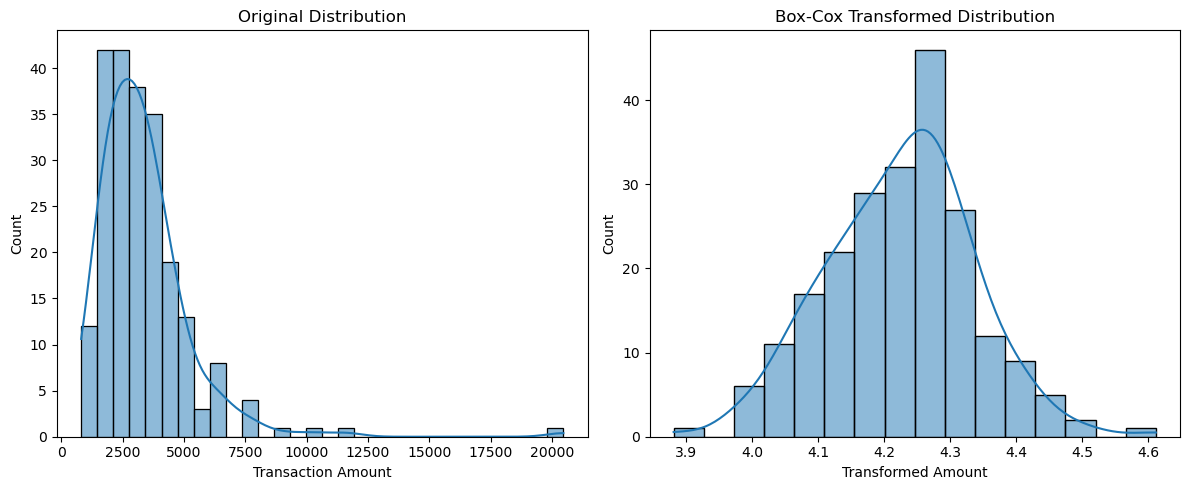

In [38]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(Amount, kde=True)
plt.title("Original Distribution")
plt.xlabel("Transaction Amount")

plt.subplot(1,2,2)
sns.histplot(Transformed, kde=True)
plt.title("Box-Cox Transformed Distribution")
plt.xlabel("Transformed Amount")

plt.tight_layout()
plt.show()

###  Z-Score Calculation and Probability of Transactions ###

In [39]:


from scipy import stats

Amount = df['transaction_amount']

mean = Amount.mean()
std = Amount.std()

print("Mean:", mean)
print("Standard Deviation:", std)



df['Z_Score'] = (Amount - mean) / std

print("\nZ-Score Calculation")
print(df[['transaction_amount', 'Z_Score']].head(10))



df['Probability'] = stats.norm.cdf(df['Z_Score'])

print("\nTransaction Probability")
print(df[['transaction_amount', 'Z_Score', 'Probability']].head(10))



print("\nFinal Analysis")
print("-------------------------")
print("Total Transactions:", len(df))
print("Average Amount:", round(mean, 2))
print("Minimum Z-Score:", round(df['Z_Score'].min(), 2))
print("Maximum Z-Score:", round(df['Z_Score'].max(), 2))
print("Average Probability:", round(df['Probability'].mean(), 4))

Mean: 3365.1924090909088
Standard Deviation: 1985.7054091615962

Z-Score Calculation
   transaction_amount   Z_Score
0             3821.34  0.229716
1             2781.84 -0.293776
2             4120.97  0.380609
3             6383.78  1.520159
4             2651.61 -0.359360
5             2651.63 -0.359350
6             6565.65  1.611748
7             4375.24  0.508659
8             2357.28 -0.507584
9             3909.95  0.274340

Transaction Probability
   transaction_amount   Z_Score  Probability
0             3821.34  0.229716     0.590844
1             2781.84 -0.293776     0.384465
2             4120.97  0.380609     0.648253
3             6383.78  1.520159     0.935764
4             2651.61 -0.359360     0.359663
5             2651.63 -0.359350     0.359667
6             6565.65  1.611748     0.946492
7             4375.24  0.508659     0.694504
8             2357.28 -0.507584     0.305873
9             3909.95  0.274340     0.608088

Final Analysis
-------------------------
T

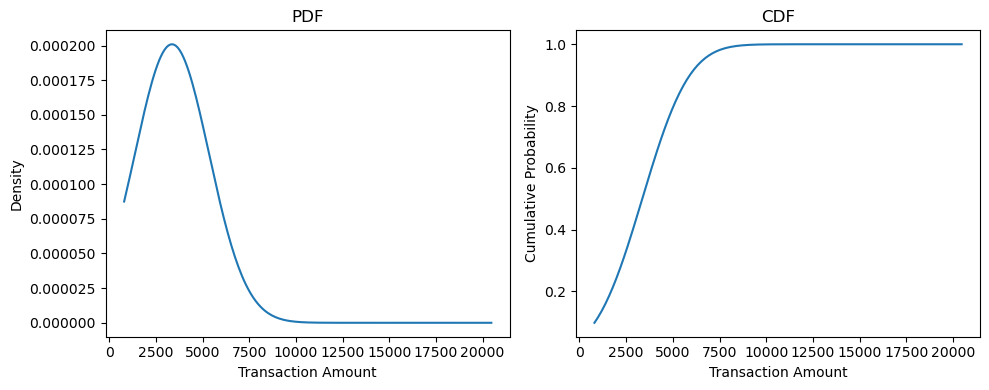

In [41]:
amount = df['transaction_amount']

avg = amount.mean()
sd = amount.std()

x = np.linspace(amount.min(), amount.max(), 200)

pdf = stats.norm.pdf(x, avg, sd)
cdf = stats.norm.cdf(x, avg, sd)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(x, pdf)
plt.title('PDF')
plt.xlabel('Transaction Amount')
plt.ylabel('Density')

plt.subplot(1, 2, 2)
plt.plot(x, cdf)
plt.title('CDF')
plt.xlabel('Transaction Amount')
plt.ylabel('Cumulative Probability')

plt.tight_layout()
plt.show()